<a href="https://colab.research.google.com/github/Nando4769/sku-4082-sim/blob/main/SKU_4082_Monte_Carlo_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

In [2]:
#attach excel
filepath = 'SKU_4082_Stochastic_Inventory_Replenishment_Model.xlsx'

In [3]:
# read the 40 week simulation ledger
df_ledger = pd.read_excel(filepath, sheet_name='SKU-4082', usecols= 'E:L')
df_ledger.columns = df_ledger.columns.str.strip() # cleans any trailing spaces in headers

#extract weeks 1-40 historical demand (excluding week 0)
hist_demand = df_ledger.loc[df_ledger['Week']>=1, 'Demand'].to_numpy(dtype=float)

In [4]:
# read model parameters from columns A & B using openpyxl
wb = openpyxl.load_workbook(filepath, data_only=True)
ws = wb['SKU-4082']

#insert the parameters
order_qty = int(ws['B15'].value)
lead_time = int(ws['B8'].value)
safety_stock = int(ws['B22'].value)
rop = int(ws['B23'].value)
mean_demand = float(ws['B20'].value)
sd_demand = float(ws['B21'].value)
inital_inventory = int(ws['I2'].value)
weeks = len(hist_demand)

print (f"Loaded {weeks} weeks | Q = {order_qty}, ROP = {rop} , SS = {safety_stock} , Mean = {mean_demand: .2f}, SD = {sd_demand: .2f}")

Loaded 40 weeks | Q = 360, ROP = 343 , SS = 67 , Mean =  138.43, SD =  28.67


In [5]:
def run_single_trial(demand_series, rop=344, stochastic_lt=False, delay_prob=0.15, rng=None):
    """
    Simulates a 40-week (s, Q) replenishment policy with explicit ROP parameter.
    """
    n_weeks = len(demand_series)
    end_on_hand = np.zeros(n_weeks + 1)
    end_on_hand[0] = inital_inventory
    arrivals = np.zeros(n_weeks + 6)
    total_lost = 0.0

    for t in range(1, n_weeks + 1):
        beg_inv = end_on_hand[t - 1] + arrivals[t]
        demand = demand_series[t - 1]
        end_inv = max(0.0, beg_inv - demand)
        lost = max(0.0, demand - beg_inv)

        end_on_hand[t] = end_inv
        total_lost += lost

        inv_position = end_inv + np.sum(arrivals[t + 1:])

        if inv_position <= rop:
            if stochastic_lt and rng is not None:
                lt = 3 if rng.random() < delay_prob else lead_time
            else:
                lt = lead_time
            arrivals[t + lt] += order_qty

    fill_rate = 1.0 - (total_lost / np.sum(demand_series))
    return end_on_hand, total_lost, fill_rate


def run_monte_carlo(rop=344, n_trials=5000, stochastic_lt=False, delay_prob=0.15, seed=42):
    """
    Runs n_trials of 40-week stochastic replenishment simulations for a given ROP.
    """
    rng = np.random.default_rng(seed)
    all_paths = np.zeros((n_trials, weeks + 1))
    min_inv_list = np.zeros(n_trials)
    lost_sales_list = np.zeros(n_trials)
    fill_rate_list = np.zeros(n_trials)

    for i in range(n_trials):
        sim_demand = np.maximum(0.0, np.round(rng.normal(mean_demand, sd_demand, size=weeks)))
        end_inv, lost, fr = run_single_trial(
            sim_demand,
            rop=rop,
            stochastic_lt=stochastic_lt,
            delay_prob=delay_prob,
            rng=rng
        )
        all_paths[i] = end_inv
        min_inv_list[i] = end_inv.min()
        lost_sales_list[i] = lost
        fill_rate_list[i] = fr

    results_df = pd.DataFrame({
        'min_ending_inv': min_inv_list,
        'total_lost_sales': lost_sales_list,
        'fill_rate': fill_rate_list,
        'had_stockout': (lost_sales_list > 0).astype(int)
    })
    return results_df, all_paths


# Run all three regimes cleanly with explicit ROP arguments
df_demand_only, paths_demand_only = run_monte_carlo(rop=344, n_trials=5000, stochastic_lt=False, seed=42)
df_with_delays, paths_with_delays = run_monte_carlo(rop=344, n_trials=5000, stochastic_lt=True, delay_prob=0.15, seed=42)
df_mitigated, paths_mitigated     = run_monte_carlo(rop=405, n_trials=5000, stochastic_lt=True, delay_prob=0.15, seed=42)

print("=== POLICY UPGRADE IMPACT (UNDER 15% CARRIER DELAY) ===")
print(f"Baseline (ROP=344, SS=67)   -> Fill Rate: {df_with_delays['fill_rate'].mean():.2%} | Stockout Window Prob: {df_with_delays['had_stockout'].mean():.1%} | Avg Lost: {df_with_delays['total_lost_sales'].mean():.1f} units")
print(f"Mitigated (ROP=405, SS=107) -> Fill Rate: {df_mitigated['fill_rate'].mean():.2%} | Stockout Window Prob: {df_mitigated['had_stockout'].mean():.1%} | Avg Lost: {df_mitigated['total_lost_sales'].mean():.1f} units\n")

=== POLICY UPGRADE IMPACT (UNDER 15% CARRIER DELAY) ===
Baseline (ROP=344, SS=67)   -> Fill Rate: 98.74% | Stockout Window Prob: 73.2% | Avg Lost: 70.1 units
Mitigated (ROP=405, SS=107) -> Fill Rate: 99.61% | Stockout Window Prob: 42.2% | Avg Lost: 21.7 units



In [6]:
SAFETY_STOCK = 67
ROP = 344

def run_monte_carlo(n_trials=5000, stochastic_lt=False, delay_prob=0.15, seed=42):
    """
    Runs n_trials of 40-week stochastic replenishment simulations.
    Returns a summary DataFrame of trial metrics and a matrix of ending inventory paths.
    """
    rng = np.random.default_rng(seed)

    all_paths = np.zeros((n_trials, weeks + 1))
    min_inv_list = np.zeros(n_trials)
    lost_sales_list = np.zeros(n_trials)
    fill_rate_list = np.zeros(n_trials)

    for i in range(n_trials):
        # Generate 40 weeks of random discrete demand
        sim_demand = np.maximum(0.0, np.round(rng.normal(mean_demand, sd_demand, size=weeks)))

        end_inv, lost, fr = run_single_trial(
            sim_demand,
            stochastic_lt=stochastic_lt,
            delay_prob=delay_prob,
            rng=rng
        )

        all_paths[i] = end_inv
        min_inv_list[i] = end_inv.min()
        lost_sales_list[i] = lost
        fill_rate_list[i] = fr

    results_df = pd.DataFrame({
        'min_ending_inv': min_inv_list,
        'total_lost_sales': lost_sales_list,
        'fill_rate': fill_rate_list,
        'had_stockout': (lost_sales_list > 0).astype(int)
    })
    return results_df, all_paths

# Run Scenario A (Demand Volatility Only) & Scenario B (Demand + 15% Carrier Delay)
df_demand_only, paths_demand_only = run_monte_carlo(n_trials=5000, stochastic_lt=False, seed=42)
df_with_delays, paths_with_delays = run_monte_carlo(n_trials=5000, stochastic_lt=True, delay_prob=0.15, seed=42)

# Print executive comparison table
summary_table = pd.DataFrame({
    'Metric': [
        'Mean Fill Rate (%)',
        'Worst 5% Fill Rate (5th Pct)',
        '40-Week Window Stockout Prob (%)',
        'Avg Lost Sales per 40 Wks (Units)',
        '95th Pct Lost Sales (Units)',
        'Median Min On-Hand (Units)'
    ],
    'Scenario A: Demand Volatility Only (Fixed L=2)': [
        f"{df_demand_only['fill_rate'].mean():.2%}",
        f"{np.percentile(df_demand_only['fill_rate'], 5):.2%}",
        f"{df_demand_only['had_stockout'].mean():.1%}",
        f"{df_demand_only['total_lost_sales'].mean():.1f}",
        f"{np.percentile(df_demand_only['total_lost_sales'], 95):.0f}",
        f"{df_demand_only['min_ending_inv'].median():.0f}"
    ],
    'Scenario B: Demand + 15% Carrier Delay (L=2 or 3)': [
        f"{df_with_delays['fill_rate'].mean():.2%}",
        f"{np.percentile(df_with_delays['fill_rate'], 5):.2%}",
        f"{df_with_delays['had_stockout'].mean():.1%}",
        f"{df_with_delays['total_lost_sales'].mean():.1f}",
        f"{np.percentile(df_with_delays['total_lost_sales'], 95):.0f}",
        f"{df_with_delays['min_ending_inv'].median():.0f}"
    ]
})

print(summary_table.to_string(index=False))

                           Metric Scenario A: Demand Volatility Only (Fixed L=2) Scenario B: Demand + 15% Carrier Delay (L=2 or 3)
               Mean Fill Rate (%)                                         99.97%                                            98.74%
     Worst 5% Fill Rate (5th Pct)                                         99.79%                                            96.00%
 40-Week Window Stockout Prob (%)                                           9.6%                                             73.2%
Avg Lost Sales per 40 Wks (Units)                                            1.6                                              70.1
      95th Pct Lost Sales (Units)                                             12                                               224
       Median Min On-Hand (Units)                                             37                                                 0


=== POLICY UPGRADE IMPACT (UNDER 15% CARRIER DELAY) ===
Baseline (ROP=344, SS=67)   -> Fill Rate: 98.74% | Stockout Window Prob: 73.2% | Avg Lost: 70.1 units
Mitigated (ROP=405, SS=107) -> Fill Rate: 99.61% | Stockout Window Prob: 42.2% | Avg Lost: 21.7 units



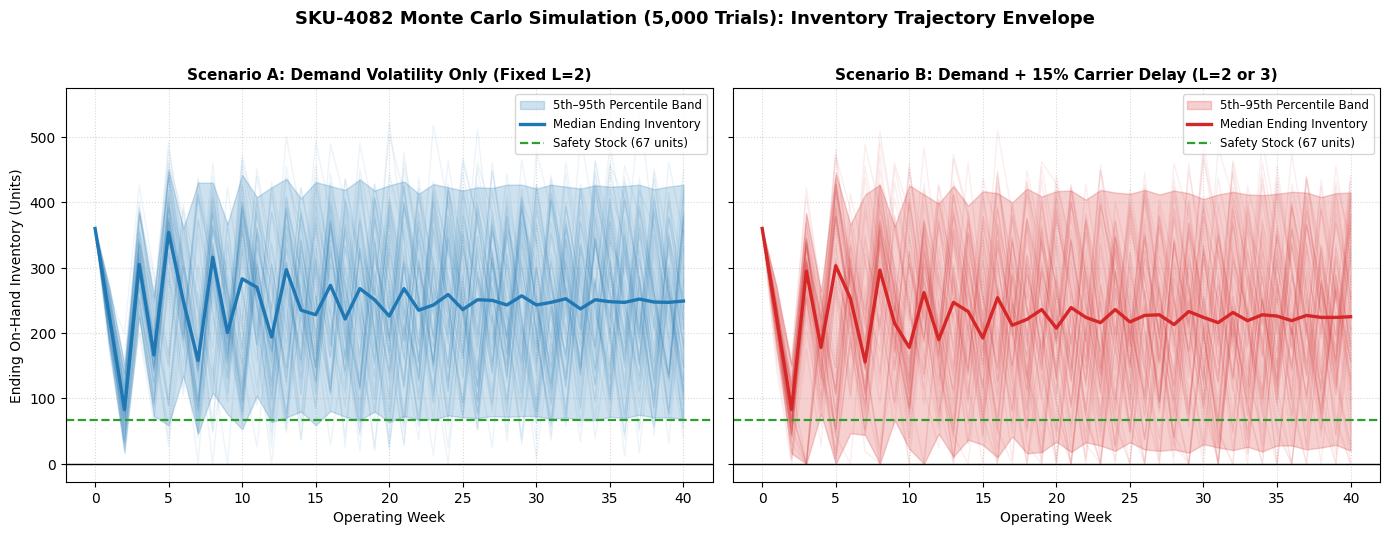

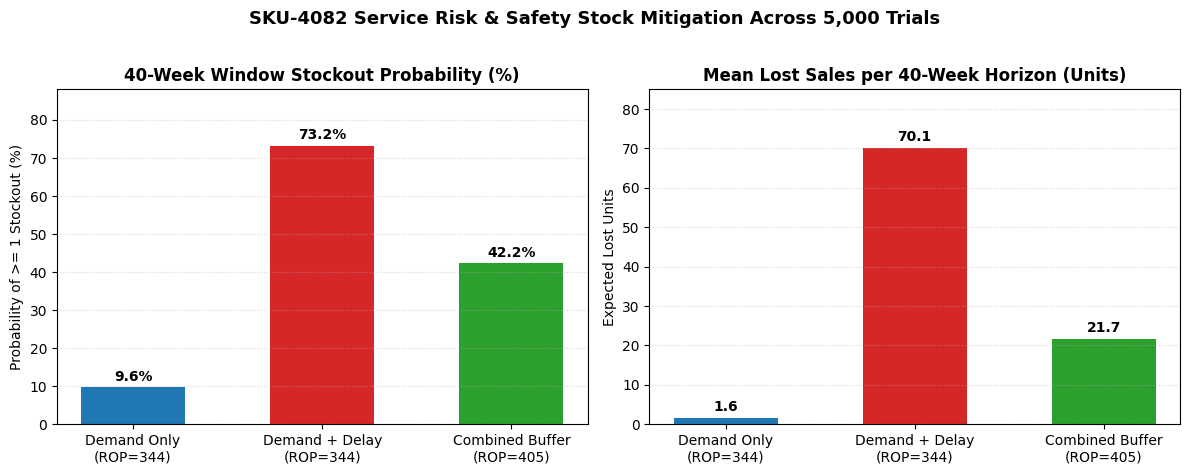

In [9]:
# 1. Unified function to make sure we don't have conflicting definitions
def run_monte_carlo_with_rop(rop=344, n_trials=5000, stochastic_lt=False, delay_prob=0.15, seed=42):
    """
    Runs n_trials of 40-week stochastic replenishment simulations for a given ROP.
    """
    rng = np.random.default_rng(seed)
    all_paths = np.zeros((n_trials, weeks + 1))
    min_inv_list = np.zeros(n_trials)
    lost_sales_list = np.zeros(n_trials)
    fill_rate_list = np.zeros(n_trials)

    for i in range(n_trials):
        sim_demand = np.maximum(0.0, np.round(rng.normal(mean_demand, sd_demand, size=weeks)))
        end_inv, lost, fr = run_single_trial(
            sim_demand,
            rop=rop,
            stochastic_lt=stochastic_lt,
            delay_prob=delay_prob,
            rng=rng
        )
        all_paths[i] = end_inv
        min_inv_list[i] = end_inv.min()
        lost_sales_list[i] = lost
        fill_rate_list[i] = fr

    results_df = pd.DataFrame({
        'min_ending_inv': min_inv_list,
        'total_lost_sales': lost_sales_list,
        'fill_rate': fill_rate_list,
        'had_stockout': (lost_sales_list > 0).astype(int)
    })
    return results_df, all_paths

# Run all three scenarios cleanly
ROP_COMBINED = 405
SS_COMBINED = 107

df_demand_only, paths_demand_only = run_monte_carlo_with_rop(rop=344, n_trials=5000, stochastic_lt=False, seed=42)
df_with_delays, paths_with_delays = run_monte_carlo_with_rop(rop=344, n_trials=5000, stochastic_lt=True, delay_prob=0.15, seed=42)
df_mitigated, paths_mitigated     = run_monte_carlo_with_rop(rop=ROP_COMBINED, n_trials=5000, stochastic_lt=True, delay_prob=0.15, seed=42)

print("=== POLICY UPGRADE IMPACT (UNDER 15% CARRIER DELAY) ===")
print(f"Baseline (ROP=344, SS=67)   -> Fill Rate: {df_with_delays['fill_rate'].mean():.2%} | Stockout Window Prob: {df_with_delays['had_stockout'].mean():.1%} | Avg Lost: {df_with_delays['total_lost_sales'].mean():.1f} units")
print(f"Mitigated (ROP=405, SS=107) -> Fill Rate: {df_mitigated['fill_rate'].mean():.2%} | Stockout Window Prob: {df_mitigated['had_stockout'].mean():.1%} | Avg Lost: {df_mitigated['total_lost_sales'].mean():.1f} units\n")

# 2. Chart 1: Stochastic Inventory Fan Chart (Scenario A vs Scenario B)
weeks_axis = np.arange(0, weeks + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)

scenarios = [
    (axes[0], paths_demand_only, 'Scenario A: Demand Volatility Only (Fixed L=2)', '#1f77b4'),
    (axes[1], paths_with_delays, 'Scenario B: Demand + 15% Carrier Delay (L=2 or 3)', '#d62728')
]

for ax, paths, title, color in scenarios:
    # Plot 60 sample trajectories lightly in background
    ax.plot(weeks_axis, paths[:60].T, color=color, alpha=0.08, linewidth=1)
    # Plot 5th-95th percentile confidence band and median path
    p5 = np.percentile(paths, 5, axis=0)
    p50 = np.percentile(paths, 50, axis=0)
    p95 = np.percentile(paths, 95, axis=0)
    ax.fill_between(weeks_axis, p5, p95, color=color, alpha=0.22, label='5th–95th Percentile Band')
    ax.plot(weeks_axis, p50, color=color, linewidth=2.4, label='Median Ending Inventory')
    ax.axhline(SAFETY_STOCK, color='#2ca02c', linestyle='--', linewidth=1.6, label=f'Safety Stock ({SAFETY_STOCK} units)')
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Operating Week')
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper right', fontsize=8.5)

axes[0].set_ylabel('Ending On-Hand Inventory (Units)')
fig.suptitle('SKU-4082 Monte Carlo Simulation (5,000 Trials): Inventory Trajectory Envelope', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('monte_carlo_trajectories.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Chart 2: Executive Risk Comparison Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

labels = ['Demand Only\n(ROP=344)', 'Demand + Delay\n(ROP=344)', 'Combined Buffer\n(ROP=405)']
stockout_probs = [
    df_demand_only['had_stockout'].mean() * 100,
    df_with_delays['had_stockout'].mean() * 100,
    df_mitigated['had_stockout'].mean() * 100
]
avg_lost = [
    df_demand_only['total_lost_sales'].mean(),
    df_with_delays['total_lost_sales'].mean(),
    df_mitigated['total_lost_sales'].mean()
]
colors = ['#1f77b4', '#d62728', '#2ca02c']

bars1 = ax1.bar(labels, stockout_probs, color=colors, width=0.55)
ax1.set_title('40-Week Window Stockout Probability (%)', fontweight='bold')
ax1.set_ylabel('Probability of >= 1 Stockout (%)')
ax1.set_ylim(0, 88)
ax1.grid(axis='y', linestyle=':', alpha=0.5)
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 1.8, f'{h:.1f}%', ha='center', fontweight='bold')

bars2 = ax2.bar(labels, avg_lost, color=colors, width=0.55)
ax2.set_title('Mean Lost Sales per 40-Week Horizon (Units)', fontweight='bold')
ax2.set_ylabel('Expected Lost Units')
ax2.set_ylim(0, 85)
ax2.grid(axis='y', linestyle=':', alpha=0.5)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1.8, f'{h:.1f}', ha='center', fontweight='bold')

fig.suptitle('SKU-4082 Service Risk & Safety Stock Mitigation Across 5,000 Trials', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('monte_carlo_risk_comparison.png', dpi=300, bbox_inches='tight')
plt.show()